In [1]:
from typing import Iterable

import numpy as np
from matplotlib import pyplot as plt
import torch
import torch.nn as nn
import pennylane as qp

from mitiq.zne.scaling import fold_global
from mitiq.zne.inference import LinearFactory

from qiskit import transpile, QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit_aer import AerSimulator
from qiskit.circuit.library import ZFeatureMap, EfficientSU2
from qiskit.quantum_info import SparsePauliOp

from qiskit.primitives import BaseEstimatorV2, BackendEstimatorV2
from qiskit.primitives.containers import PrimitiveResult, PubResult
from qiskit.primitives.containers.estimator_pub import EstimatorPub
from qiskit_aer.primitives import EstimatorV2 as Estimator

from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.connectors import TorchConnector
from qiskit_algorithms.gradients import ReverseEstimatorGradient

from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2
from qiskit_ibm_runtime.options import EstimatorOptions
from qiskit.providers import JobStatus
import random

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

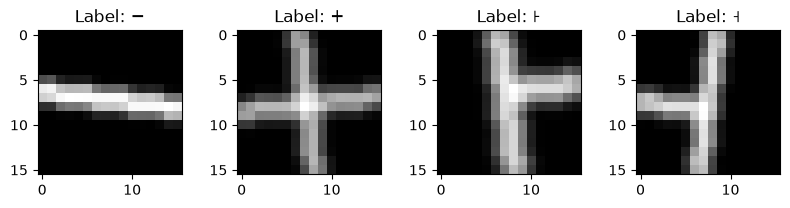

In [2]:
#loading dataset
[pm] = qp.data.load('other', name='plus-minus')

X_train = pm.img_train  # shape (1000,16,16)
X_test = pm.img_test  # shape (200,16,16)
Y_train = pm.labels_train  # shape (1000,)
Y_test = pm.labels_test  # shape (200,)

x_vis = [
    (X_train[Y_train == 0])[0],
    (X_train[Y_train == 1])[0],
    (X_train[Y_train == 2])[0],
    (X_train[Y_train == 3])[0],
]
y_vis = [0, 1, 2, 3]

#visualizing each class
def visualize_data(x, y, pred=None):
    n_img = len(x)
    labels_list = ["\u2212", "\u002b", "\ua714", "\u02e7"]
    fig, axes = plt.subplots(1, 4, figsize=(8, 2))
    for i in range(n_img):
        axes[i].imshow(x[i], cmap="gray")
        if pred is None:
            axes[i].set_title("Label: {}".format(labels_list[y[i]]))
        else:
            axes[i].set_title("Label: {}, Pred: {}".format(labels_list[y[i]], labels_list[pred[i]]))
    plt.tight_layout(w_pad=2)
    plt.show()

visualize_data(x_vis, y_vis)

In [3]:
#exact estimation no noise
class QiskitReuploadingClassifier(nn.Module):
    def __init__(self, input_dim=256, output_dim=4, num_qubits=8, num_layers=2, num_reup=3, estimator=None, backend=None):
        super().__init__()
        self.num_qubits = num_qubits
        self.output_dim = output_dim
        self.num_layers = num_layers
        self.num_reup = num_reup
        
        #3 rotations per qubit per layer
        self.total_angles = num_layers * num_qubits * 3
        self.input_projection = nn.Linear(input_dim, self.total_angles)
    
        self.weights = nn.Parameter(0.1 * torch.rand(self.total_angles))
        self.bias = nn.Parameter(0.1 * torch.rand(self.total_angles))
        
        self.qc, self.params = self._build_strongly_entangling_circuit()
        if backend is not None:
            self.qc = transpile(
                self.qc,
                backend=backend,
                optimization_level=0,
                seed_transpiler=42,
            )

        self.params = list(self.qc.parameters)
        
        self.observables = [SparsePauliOp.from_sparse_list([("Z", [i], 1)],num_qubits=self.num_qubits,) for i in range(self.output_dim)]

        if backend is not None and self.qc.layout is not None:
            self.observables = [
                obs.apply_layout(self.qc.layout)
                for obs in self.observables
            ]
        print(self.qc.num_qubits)
        print(self.qc.num_parameters)
        qnn = EstimatorQNN(
            circuit=self.qc,
            observables=self.observables,
            input_params=self.params,
            weight_params=[],
            estimator=estimator,
            input_gradients=True,
            gradient=ReverseEstimatorGradient(),  
        )
        
        self.qcircuit = TorchConnector(qnn)

    #the same implementation as strongly entangling circuit function from pennylane
    def _build_strongly_entangling_circuit(self):
     qc = QuantumCircuit(self.num_qubits)
     params = ParameterVector('θ', self.total_angles)
        
     idx = 0
     for layer in range(self.num_layers):
        for q in range(self.num_qubits):
             qc.rz(params[idx], q)
             qc.ry(params[idx+1], q)
             qc.rz(params[idx+2], q)
             idx += 3
                
        step = (layer % (self.num_qubits - 1)) + 1
        for q in range(self.num_qubits):
            target = (q + step) % self.num_qubits
            qc.cx(q, target)
                
     return qc, params

    def forward(self, x):
        angles = self.input_projection(x)
        angles = self.weights * angles + self.bias
        return self.qcircuit(angles)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = QiskitReuploadingClassifier().to(device)

dummy_data = torch.rand(5, 256).to(device) 
output = model(dummy_data)

print("Output shape:", output.shape) # Expected: [5, 4]

Using device: cpu
8
48
Output shape: torch.Size([5, 4])


In [4]:
#instantiating the model
input_dim = 256
num_classes = 4
num_qubits = 8
num_layers = 2

qml_model = QiskitReuploadingClassifier(
    input_dim=input_dim, 
    output_dim=num_classes,     
    num_qubits=num_qubits, 
    num_layers=num_layers,
).to(device)


8
48


In [5]:
# Hyperparameters 
learning_rate = 0.05
epochs = 3
batch_size = 20
input_dim = 256
num_classes = 4
num_qubits = 8
num_layers = 2

feats_train = torch.from_numpy(X_train[:200]).reshape(200, -1).float().to(device)
feats_test = torch.from_numpy(X_test[:50]).reshape(50, -1).float().to(device)
labels_train = torch.from_numpy(Y_train[:200]).long().to(device)
labels_test = torch.from_numpy(Y_test[:50]).long().to(device)
num_train = feats_train.shape[0]

qml_model = QiskitReuploadingClassifier(
    input_dim=input_dim, 
    output_dim=num_classes, 
    num_qubits=num_qubits, 
    num_layers=num_layers,
).to(device)


loss = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(qml_model.parameters(), lr=learning_rate)
num_batches = num_train // batch_size

def accuracy(labels, predictions):
    predicted_classes = torch.argmax(predictions, dim=1)
    correct = (predicted_classes == labels).sum().item()
    return correct / len(labels)

def gen_batches(num_samples, num_batches):
    assert num_samples % num_batches == 0
    perm_ind = torch.reshape(torch.randperm(num_samples), (num_batches, -1))
    return perm_ind


def print_acc(epoch, max_ep=4):
    with torch.no_grad():
        predictions_train = qml_model(feats_train[:50])
        predictions_test = qml_model(feats_test)
        
        cost_approx_train = loss(predictions_train, labels_train[:50])
        cost_approx_test = loss(predictions_test, labels_test)
        
        acc_approx_train = accuracy(labels_train[:50], predictions_train)
        acc_approx_test = accuracy(labels_test, predictions_test)
        
    print(
        f"Epoch {epoch}/{max_ep} | Approx Cost (train): {cost_approx_train:0.7f} | Cost (val): {cost_approx_test:0.7f} |"
        f" Approx Acc train: {acc_approx_train:0.7f} | Acc val: {acc_approx_test:0.7f}"
    )


8
48


Starting training loop for Qiskit variational classifier (8 qubits, 2 layers)...
Epoch 0/3 | Approx Cost (train): 1.3864183 | Cost (val): 1.3856709 | Approx Acc train: 0.2000000 | Acc val: 0.2800000
Epoch 1/3 | Approx Cost (train): 0.8457485 | Cost (val): 0.8512890 | Approx Acc train: 0.9600000 | Acc val: 0.9800000
Epoch 2/3 | Approx Cost (train): 0.7214705 | Cost (val): 0.7075105 | Approx Acc train: 0.9600000 | Acc val: 0.9800000
Epoch 3/3 | Approx Cost (train): 0.6815174 | Cost (val): 0.6905354 | Approx Acc train: 0.9200000 | Acc val: 0.9800000


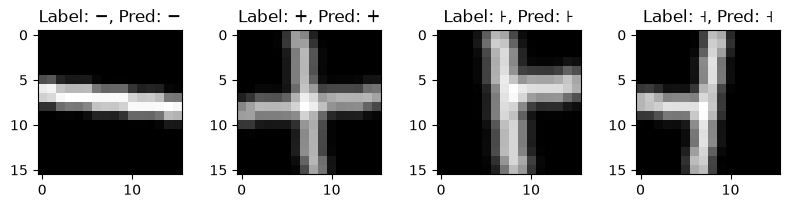

In [6]:
print(f"Starting training loop for Qiskit variational classifier ({num_qubits} qubits, {num_layers} layers)...")

for ep in range(epochs):
    batch_ind = gen_batches(num_train, num_batches)
    print_acc(epoch=ep, max_ep=epochs)

    for it in range(num_batches):
        optimizer.zero_grad()
        
        feats_train_batch = feats_train[batch_ind[it]]
        labels_train_batch = labels_train[batch_ind[it]]
        outputs = qml_model(feats_train_batch)
        batch_loss = loss(outputs, labels_train_batch)
        batch_loss.backward()
        optimizer.step()

print_acc(epochs, max_ep=epochs)

x_vis_torch = torch.from_numpy(np.array(x_vis).reshape(4, -1)).float().to(device)
y_vis_torch = torch.from_numpy(np.array(y_vis)).long().to(device)

with torch.no_grad():
    benign_preds = qml_model(x_vis_torch)

benign_class_output = torch.argmax(benign_preds, dim=1).cpu().numpy()
visualize_data(x_vis, y_vis, benign_class_output)

In [7]:
save_path = "qiskit_reuploading_classifier.pth"
torch.save({
    "model_state_dict": qml_model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epoch": epochs,
    "learning_rate": learning_rate,
}, save_path)
print(f"Model weights saved to {save_path}")

Model weights saved to qiskit_reuploading_classifier.pth


In [93]:
#if training is skipped
checkpoint = torch.load("qiskit_reuploading_classifier.pth", map_location=device)

qml_model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
start_epoch = checkpoint["epoch"]

feats_train = torch.from_numpy(X_train[:200]).reshape(200, -1).float().to(device)
feats_test = torch.from_numpy(X_test[:50]).reshape(50, -1).float().to(device)
labels_train = torch.from_numpy(Y_train[:200]).long().to(device)
labels_test = torch.from_numpy(Y_test[:50]).long().to(device)

x_vis_torch = torch.from_numpy(np.array(x_vis).reshape(4, -1)).float().to(device)
y_vis_torch = torch.from_numpy(np.array(y_vis)).long().to(device)

In [94]:
qml_model.eval() 

with torch.no_grad():
    adversarial_preds_before = qml_model(feats_test)

adversarial_class_output_before = torch.argmax(adversarial_preds_before, dim=1)
acc = accuracy(labels_test, adversarial_preds_before)
print(f"Accuracy before PGD Attack: {acc:0.4f}")

Accuracy before PGD Attack: 0.9800


In [95]:
#PGD attack
loss_fn = nn.CrossEntropyLoss()

def PGD(model, feats, labels, epsilon=0.05, alpha=0.01, num_iter=5):
    model.eval()

    delta = torch.zeros_like(feats, requires_grad=True)

    for _ in range(num_iter):
        model.zero_grad()

        outputs = model(feats + delta)
        loss = loss_fn(outputs, labels)
        loss.backward()

        with torch.no_grad():
            delta += alpha * delta.grad.sign()
            delta.clamp_(-epsilon, epsilon)

        delta.grad.zero_()

    return delta.detach()

In [96]:
perturbations_test = PGD(model=qml_model, feats=feats_test, labels=labels_test, epsilon=0.05)
perturbed_feats_test = feats_test + perturbations_test
qml_model.eval()

with torch.no_grad():
    adversarial_preds_after = qml_model(perturbed_feats_test)

adversarial_class_output_after = torch.argmax(adversarial_preds_after, dim=1)
adv_acc = accuracy(labels_test, adversarial_preds_after)
print(f"Accuracy AFTER PGD Attack: {adv_acc:0.4f}")

Accuracy AFTER PGD Attack: 0.8600


In [44]:
adv_dataset = (
    PGD(model=qml_model, feats=feats_train[:50], labels=labels_train[:50], epsilon=0.05)
    + feats_train[:50]
)

feats_retrain = torch.cat((feats_train, adv_dataset))
labels_retrain = torch.cat((labels_train, labels_train[:50]))
epochs_retraining = 3

for ep in range(0, epochs_retraining):
    batch_ind = gen_batches(num_train, num_batches)
    print_acc(epoch=ep, max_ep=3)

    for it in range(num_batches):
        optimizer.zero_grad()
        feats_train_batch = feats_retrain[batch_ind[it]]
        labels_train_batch = labels_retrain[batch_ind[it]]

        outputs = qml_model(feats_train_batch)
        batch_loss = loss(outputs, labels_train_batch)
        # if REG:
        #    loss = loss + lipschitz_regularizer(regularization_rate, model.qcircuit.weights)
        batch_loss.backward()
        optimizer.step()

print_acc(epochs_retraining, max_ep=3)


Epoch 0/3 | Approx Cost (train): 0.6815174 | Cost (val): 0.6905354 | Approx Acc train: 0.9200000 | Acc val: 0.9800000
Epoch 1/3 | Approx Cost (train): 0.6592197 | Cost (val): 0.6361489 | Approx Acc train: 0.9400000 | Acc val: 0.9800000
Epoch 2/3 | Approx Cost (train): 0.6442170 | Cost (val): 0.6318835 | Approx Acc train: 0.9200000 | Acc val: 0.9800000
Epoch 3/3 | Approx Cost (train): 0.6278380 | Cost (val): 0.6229942 | Approx Acc train: 0.9200000 | Acc val: 0.9800000


In [45]:
save_path = "qiskit_reuploading_classifier_after_attack.pth"
torch.save({
    "model_state_dict": qml_model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epoch": epochs,
    "learning_rate": learning_rate,
}, save_path)
print(f"Model weights saved to {save_path}")

Model weights saved to qiskit_reuploading_classifier_after_attack.pth


In [46]:
#if training is skiped
checkpoint = torch.load("qiskit_reuploading_classifier_after_attack.pth", map_location=device)

qml_model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
start_epoch = checkpoint["epoch"]

In [51]:
qml_model.eval()

with torch.no_grad():
    adversarial_preds_after = qml_model(perturbed_feats_test)

adversarial_class_output_after = torch.argmax(adversarial_preds_after, dim=1)
adv_acc = accuracy(labels_test, adversarial_preds_after)
print(f"Accuracy AFTER PGD Attack: {adv_acc:0.4f}")

Accuracy AFTER PGD Attack: 0.9000


In [52]:
perturbations_test = PGD(model=qml_model, feats=feats_test, labels=labels_test, epsilon=0.05)
perturbed_feats_test = feats_test + perturbations_test
print(perturbations_test.abs().max())
print(perturbations_test.abs().mean())
qml_model.eval()
#tensor(0.0500)
#tensor(0.0448)

with torch.no_grad():
    adversarial_preds_after = qml_model(perturbed_feats_test)

adversarial_class_output_after = torch.argmax(adversarial_preds_after, dim=1)
adv_acc = accuracy(labels_test, adversarial_preds_after)
print(f"Accuracy AFTER PGD Attack: {adv_acc:0.4f}")
qml_model.train()


tensor(0.0500)
tensor(0.0462)
Accuracy AFTER PGD Attack: 0.7400


QiskitReuploadingClassifier(
  (input_projection): Linear(in_features=256, out_features=48, bias=True)
  (qcircuit): TorchConnector()
)

In [12]:
class _SynchronousJob:
    def __init__(self, result_data):
        self._result_data = result_data

    def result(self):
        return self._result_data
    
    def status(self):
        return JobStatus.DONE

class MitiqZNEEstimatorV2(BaseEstimatorV2):

    def __init__(self, backend, noise_factors=(1.0, 3.0, 5.0), max_pubs_per_run=12):
        super().__init__()
        self.backend = backend
        self.base_estimator = BackendEstimatorV2(backend=backend)
        self.noise_factors = tuple(float(x) for x in noise_factors)

        if len(self.noise_factors) == 0:
            raise ValueError("noise_factors cannot be empty.")

        for scale in self.noise_factors:
            if not float(scale).is_integer():
                raise ValueError("This implementation requires integer noise factors. Use e.g. (1, 3, 5).")
            scale = int(scale)
            if scale < 1 or scale % 2 == 0:
                raise ValueError("Noise factors must be positive odd integers, e.g. (1, 3, 5).")

        self.max_pubs_per_run = int(max_pubs_per_run)

        if self.max_pubs_per_run < len(self.noise_factors):
            raise ValueError("max_pubs_per_run must be >= len(noise_factors).")

        self._folded_cache = {}
        self.zne_coefficients = self._compute_zne_coefficients(self.noise_factors)

    def run(self, pubs, *, precision=None, **run_options):
        result = self._run_mitiq(pubs, precision=precision, **run_options)
        return _SynchronousJob(result)

    @staticmethod
    def _compute_zne_coefficients(noise_factors):
        """
        Compute coefficients c_i such that
            E_ZNE = sum_i c_i E(noise_factor_i)
        corresponds to Lagrange extrapolation at zero noise.
        """
        x = np.asarray(noise_factors, dtype=np.float64)
        coefficients = np.ones(len(x), dtype=np.float64)

        for i in range(len(x)):
            for j in range(len(x)):
                if i == j:
                    continue
                coefficients[i] *= (-x[j] / (x[i] - x[j]))

        return coefficients

    @staticmethod
    def _make_parameter_dict(bindings, row):
        param_dict = {}
        for keys, values in bindings.data.items():
            row_values = values[row] if bindings.shape else values
            if isinstance(keys, tuple):
                for key, value in zip(keys, row_values):
                    param_dict[key] = value
            else:
                param_dict[keys] = row_values
        return param_dict

    @staticmethod
    def _bind_parameter_dict(circuit, param_dict):
        return circuit.assign_parameters(param_dict, strict=False)

    @staticmethod
    def _cache_key(circuit):
        instructions = []
        for instruction in circuit.data:
            op = instruction.operation
            qargs = tuple(circuit.find_bit(q).index for q in instruction.qubits)
            cargs = tuple(circuit.find_bit(c).index for c in instruction.clbits)
            params = tuple(str(parameter) for parameter in op.params)
            instructions.append((op.name, qargs, cargs, params))
        return (circuit.num_qubits, circuit.num_clbits, str(circuit.global_phase), tuple(instructions))

    def clear_cache(self):
        self._folded_cache.clear()

    @staticmethod
    def _inverse_circuit(circuit):
        """Construct U† while preserving Qiskit ParameterExpressions."""
        inverse = QuantumCircuit(circuit.num_qubits, circuit.num_clbits)
        inverse.global_phase = -circuit.global_phase

        for instruction in reversed(circuit.data):
            op = instruction.operation
            qargs = instruction.qubits
            cargs = instruction.clbits
            if op.name in {"measure", "reset", "barrier"}:
                continue
            inverse.append(op.inverse(), qargs, cargs)

        return inverse

    @classmethod
    def _fold_global_qiskit(cls, circuit, scale_factor):
        """
        Parameter-preserving global folding.
        scale 1: U
        scale 3: U U† U
        scale 5: U U† U U† U
        """
        scale = int(round(float(scale_factor)))

        if scale < 1 or scale % 2 == 0:
            raise ValueError("Global folding requires positive odd integer scale factors.")

        if scale == 1:
            return circuit.copy()

        base = QuantumCircuit(circuit.num_qubits, circuit.num_clbits)
        base.global_phase = circuit.global_phase

        for instruction in circuit.data:
            op = instruction.operation
            qargs = instruction.qubits
            cargs = instruction.clbits
            if op.name == "barrier":
                continue
            if op.name in {"measure", "reset"}:
                raise ValueError(f"Global folding requires a unitary circuit. Found {op.name}.")
            base.append(op, qargs, cargs)

        inverse = cls._inverse_circuit(base)
        folded = QuantumCircuit(base.num_qubits, base.num_clbits)
        folded.global_phase = base.global_phase
        repetitions = (scale - 1) // 2
        folded.compose(base, inplace=True)

        for _ in range(repetitions):
            folded.compose(inverse, inplace=True)
            folded.compose(base, inplace=True)

        return folded

    @staticmethod
    def _replace_sxdg(circuit):
        new_circuit = QuantumCircuit(circuit.num_qubits, circuit.num_clbits)
        new_circuit.global_phase = circuit.global_phase
        new_circuit.metadata = circuit.metadata

        for instruction in circuit.data:
            op = instruction.operation
            qargs = instruction.qubits
            cargs = instruction.clbits

            if op.name == "sxdg":
                q = qargs[0]
                new_circuit.sx(q)
                new_circuit.x(q)
            else:
                new_circuit.append(op, qargs, cargs)

        return new_circuit
    
    def _get_folded_templates(self, circuit):
        key = self._cache_key(circuit)
        cached = self._folded_cache.get(key)
        if cached is not None:
            return cached

        print("\nCreating cached ZNE templates...")
        folded_templates = {}

        for scale in self.noise_factors:
            print(f"  Folding scale {scale}")
            folded = self._fold_global_qiskit(circuit, scale)
            folded = self._replace_sxdg(folded)
            folded_templates[scale] = folded
            print(f"    qubits: {folded.num_qubits}")
            print(f"    parameters: {folded.num_parameters}")
            print(f"    depth: {folded.depth()}")

        self._folded_cache[key] = folded_templates
        return folded_templates

    def _execute_chunk(self, pubs, precision, run_options):
        if not pubs:
            return []
        job = self.base_estimator.run(pubs, precision=precision, **run_options)
        result = job.result()
        return [result[i] for i in range(len(result))]

    def _run_mitiq(self, pubs, precision=None, **run_options):
        coerced_pubs = [EstimatorPub.coerce(pub) for pub in pubs]
        batch_sizes = []
        all_base_results = []
        chunk_pubs = []
        num_factors = len(self.noise_factors)
        chunk_size = self.max_pubs_per_run

        for pub in coerced_pubs:
            circuit = pub.circuit
            observables = pub.observables
            bindings = pub.parameter_values
            batch_size = bindings.shape[0] if bindings.shape else 1
            batch_sizes.append(batch_size)
            folded_templates = self._get_folded_templates(circuit)

            for row in range(batch_size):
                param_dict = self._make_parameter_dict(bindings, row)
                for scale in self.noise_factors:
                    template = folded_templates[scale]
                    bound_circuit = self._bind_parameter_dict(template, param_dict)
                    chunk_pubs.append((bound_circuit, observables))

                if len(chunk_pubs) >= chunk_size:
                    results = self._execute_chunk(chunk_pubs, precision, run_options)
                    all_base_results.extend(results)
                    chunk_pubs = []

        if chunk_pubs:
            results = self._execute_chunk(chunk_pubs, precision, run_options)
            all_base_results.extend(results)

        expected_results = sum(batch_sizes) * num_factors
        if len(all_base_results) != expected_results:
            raise RuntimeError(f"Unexpected number of estimator results. Expected {expected_results}, received {len(all_base_results)}.")
        
        final_results = []
        result_index = 0

        for batch_size in batch_sizes:
            n_results = batch_size * num_factors
            batch_results = all_base_results[result_index:result_index + n_results]
            result_index += n_results

            evs = np.asarray([result.data.evs for result in batch_results], dtype=np.float64)
            evs = evs.reshape(batch_size, num_factors, -1)
            mitigated_evs = np.einsum("f,sfo->so", self.zne_coefficients, evs, optimize=True)
            
            data_bin_type = type(batch_results[0].data)
            data_kwargs = {"evs": mitigated_evs}

            if hasattr(batch_results[0].data, "stds"):
                data_kwargs["stds"] = np.full(mitigated_evs.shape, np.nan, dtype=mitigated_evs.dtype)

            mitigated_data = data_bin_type(**data_kwargs)
            metadata = dict(batch_results[0].metadata)
            metadata.update({"mitigated_by": "Qiskit_GlobalFold_Linear", "noise_factors": self.noise_factors, "zne_chunk_size": self.max_pubs_per_run})

            if "target_precision" not in metadata and precision is not None:
                metadata["target_precision"] = precision

            final_results.append(PubResult(mitigated_data, metadata=metadata))

        return PrimitiveResult(final_results)

In [65]:

checkpoint = torch.load( "qiskit_reuploading_classifier.pth", map_location=device, ) 
qml_model.load_state_dict(checkpoint["model_state_dict"]) 

service = QiskitRuntimeService()
real_backend = service.backend("ibm_aachen")
print(f"Target Real Backend: {real_backend.name}")

aer_backend = AerSimulator.from_backend(real_backend)
print(f"Running on AerSimulator mimicking: {real_backend.name}")

service = QiskitRuntimeService() 
hardware_estimator = MitiqZNEEstimatorV2( backend=aer_backend, 
 noise_factors=[1.0, 3.0, 5.0], ) 

transpiled_qc = transpile( qml_model.qc, 
                          backend=aer_backend, 
                          optimization_level=0,
                          seed_transpiler=42, ) 

hardware_model = QiskitReuploadingClassifier( input_dim=input_dim, 
                                             output_dim=num_classes, 
                                             num_qubits=num_qubits, 
                                             num_layers=num_layers, 
                                             estimator=hardware_estimator, 
                                             backend=aer_backend, )
hardware_model.qc = transpiled_qc 
hardware_model.load_state_dict(checkpoint["model_state_dict"]) 
hardware_model.eval()

with torch.no_grad(): 
    print("Mitiq ZNE ") 
    mitigated_predictions = hardware_model(perturbed_feats_test) 

mitigated_acc = accuracy(labels_test, mitigated_predictions) 
print(f"Simulated Mitigated Accuracy: {mitigated_acc:.4f}")

Target Real Backend: ibm_aachen
Running on AerSimulator mimicking: ibm_aachen
156
48
Mitiq ZNE 

Creating cached ZNE templates...
  Folding scale 1.0
    qubits: 156
    parameters: 48
    depth: 115
  Folding scale 3.0
    qubits: 156
    parameters: 48
    depth: 385
  Folding scale 5.0
    qubits: 156
    parameters: 48
    depth: 655
Simulated Mitigated Accuracy: 0.9000


In [97]:


service = QiskitRuntimeService( channel="ibm_cloud", private_endpoint=False)

checkpoint = torch.load("qiskit_reuploading_classifier.pth", map_location=device)
ibm_backend = service.backend("ibm_aachen")
print("Using backend:", ibm_backend.name)

hardware_estimator = EstimatorV2(
    mode=ibm_backend,
    options=EstimatorOptions(
        resilience_level=0,
        resilience={
            "zne_mitigation": True,
            "zne": {
                "noise_factors": [1.0, 3.0, 5.0],
                "extrapolator": "exponential",
            },
        },
        default_shots=1024,
    ),
)

hardware_model = QiskitReuploadingClassifier(
    input_dim=input_dim,
    output_dim=num_classes,
    num_qubits=num_qubits,
    num_layers=num_layers,
    estimator=hardware_estimator,
    backend=ibm_backend,
)

hardware_model.load_state_dict(checkpoint["model_state_dict"])
hardware_model.eval()

batch_size = 5
predictions = []

with torch.no_grad():
    for start in range(0, len(perturbed_feats_test), batch_size):
        end = min(start + batch_size, len(perturbed_feats_test))
        batch = perturbed_feats_test[start:end]

        print(f"Running samples {start}:{end}")

        batch_predictions = hardware_model(batch)
        predictions.append(batch_predictions.detach().cpu())

mitigated_predictions = torch.cat(predictions, dim=0)

mitigated_acc = accuracy(
    labels_test,
    mitigated_predictions,
)

print(f"IBM Aachen ZNE Accuracy: {mitigated_acc:.4f}")

Using backend: ibm_aachen
156
48
Running samples 0:5


RuntimeInvalidStateError: 'Unable to retrieve result for job da2rccm6uqqc73c53jsg. Job was cancelled.'

In [58]:
import torch

from qiskit_ibm_runtime import QiskitRuntimeService, Session, EstimatorV2, EstimatorOptions

checkpoint = torch.load("qiskit_reuploading_classifier.pth", map_location=device)

service = QiskitRuntimeService(channel="ibm_cloud", private_endpoint=False)
ibm_backend = service.backend("ibm_aachen")

with Session(backend=ibm_backend) as session:
    hardware_estimator = EstimatorV2(mode=session, options=EstimatorOptions(resilience_level=0, default_shots=1024))

    hardware_model = QiskitReuploadingClassifier(input_dim=input_dim, output_dim=num_classes, num_qubits=num_qubits, num_layers=num_layers, estimator=hardware_estimator, backend=ibm_backend)

    hardware_model.load_state_dict(checkpoint["model_state_dict"])
    hardware_model.eval()

    batch_size = 5
    predictions = []

    with torch.no_grad():
        for start in range(0, len(perturbed_feats_test), batch_size):
            end = min(start + batch_size, len(perturbed_feats_test))
            print(f"Running samples {start}:{end}")
            batch_predictions = hardware_model(perturbed_feats_test[start:end])
            predictions.append(batch_predictions.detach().cpu())

    predictions = torch.cat(predictions, dim=0)

accuracy_no_mitigation = accuracy(labels_test, predictions)

print(f"IBM Aachen No Mitigation Accuracy: {accuracy_no_mitigation:.4f}")

156
48
Running samples 0:5
Running samples 5:10
Running samples 10:15
Running samples 15:20
Running samples 20:25
Running samples 25:30
Running samples 30:35
Running samples 35:40
Running samples 40:45
Running samples 45:50
IBM Aachen No Mitigation Accuracy: 0.6000


In [59]:
import torch

from qiskit_ibm_runtime import QiskitRuntimeService, Session, EstimatorV2, EstimatorOptions

checkpoint = torch.load("qiskit_reuploading_classifier.pth", map_location=device)

service = QiskitRuntimeService(channel="ibm_cloud", private_endpoint=False)
ibm_backend = service.backend("ibm_aachen")

with Session(backend=ibm_backend) as session:
    hardware_estimator = EstimatorV2(mode=session, options=EstimatorOptions(resilience_level=0, resilience={"measure_mitigation": True}, default_shots=1024))

    hardware_model = QiskitReuploadingClassifier(input_dim=input_dim, output_dim=num_classes, num_qubits=num_qubits, num_layers=num_layers, estimator=hardware_estimator, backend=ibm_backend)

    hardware_model.load_state_dict(checkpoint["model_state_dict"])
    hardware_model.eval()

    batch_size = 5
    predictions = []

    with torch.no_grad():
        for start in range(0, len(perturbed_feats_test), batch_size):
            end = min(start + batch_size, len(perturbed_feats_test))
            print(f"Running samples {start}:{end}")
            batch_predictions = hardware_model(perturbed_feats_test[start:end])
            predictions.append(batch_predictions.detach().cpu())

    trex_predictions = torch.cat(predictions, dim=0)

trex_acc = accuracy(labels_test, trex_predictions)

print(f"IBM Aachen TREX Accuracy: {trex_acc:.4f}")

156
48
Running samples 0:5
Running samples 5:10
Running samples 10:15
Running samples 15:20
Running samples 20:25
Running samples 25:30
Running samples 30:35
Running samples 35:40
Running samples 40:45
Running samples 45:50
IBM Aachen TREX Accuracy: 0.6200


In [91]:
import hashlib
import numpy as np
from collections import OrderedDict
from qiskit.circuit import QuantumCircuit, Parameter
from qiskit.circuit.library import XGate, RZGate, SXGate, SXdgGate
from qiskit.primitives import BackendEstimatorV2
from qiskit.quantum_info import SparsePauliOp


class _CDRData:
    def __init__(self, value):
        self.evs = np.asarray(value)


class _CDRResult:
    def __init__(self, value):
        self.data = _CDRData(value)


class _SynchronousJob:
    def __init__(self, values):
        self._values = np.asarray(values, dtype=float).reshape(-1)

    def result(self):
        return [_CDRResult(value) for value in self._values]


class MitiqCDREstimatorV2:
    def __init__(self, backend, ideal_backend=None, num_training_circuits=8, fraction_non_clifford=0.1, random_state=42, shots=1024, max_cache_size=256, precision=None):
        self.backend = backend
        self.ideal_backend = ideal_backend if ideal_backend is not None else backend
        self.num_training_circuits = int(num_training_circuits)
        self.fraction_non_clifford = float(fraction_non_clifford)
        self.random_state = int(random_state)
        self.shots = int(shots)
        self.max_cache_size = int(max_cache_size)
        self.precision = float(precision) if precision is not None else 1.0 / np.sqrt(self.shots)
        self.noisy_estimator = BackendEstimatorV2(backend=self.backend)
        self.ideal_estimator = BackendEstimatorV2(backend=self.ideal_backend)
        self._structure_cache = OrderedDict()
        self._template_cache = OrderedDict()
        self._ideal_cache = OrderedDict()
        self._gate_cache = {
            "x": XGate(),
            "rz_pi": RZGate(np.pi),
            "rz_pi_half": RZGate(np.pi / 2),
            "rz_minus_pi_half": RZGate(-np.pi / 2),
            "sx": SXGate(),
            "sxdg": SXdgGate()
        }

    def _cache_put(self, cache, key, value):
        cache[key] = value
        cache.move_to_end(key)

        while len(cache) > self.max_cache_size:
            cache.popitem(last=False)

    def _structure_key(self, circuit):
        cache_key = id(circuit)

        cached = self._structure_cache.get(cache_key)

        if cached is not None:
            return cached

        signature = []

        for inst in circuit.data:
            op = inst.operation
            qargs = tuple(circuit.find_bit(q).index for q in inst.qubits)
            cargs = tuple(circuit.find_bit(c).index for c in inst.clbits)

            params = []

            for p in getattr(op, "params", []):
                if isinstance(p, Parameter):
                    params.append(("p", str(p)))
                elif hasattr(p, "parameters") and p.parameters:
                    params.append(("e", str(p)))
                else:
                    try:
                        params.append(("v", float(p)))
                    except Exception:
                        params.append(("v", str(p)))

            signature.append((op.name, qargs, cargs, tuple(params)))

        key = hashlib.sha256(
            repr(
                (
                    circuit.num_qubits,
                    circuit.num_clbits,
                    tuple(signature)
                )
            ).encode()
        ).hexdigest()

        self._cache_put(self._structure_cache, cache_key, key)

        return key

    @staticmethod
    def _parameterized(op):
        return any(
            isinstance(p, Parameter) or
            (hasattr(p, "parameters") and p.parameters)
            for p in getattr(op, "params", [])
        )

    @staticmethod
    def _eligible(inst):
        return (
            inst.operation.name.lower() in {"x", "y", "z", "h", "s", "sdg"}
            and not MitiqCDREstimatorV2._parameterized(inst.operation)
        )

    @staticmethod
    def _replacement(name):
        replacements = {
            "x": ("x",),
            "y": ("rz_pi", "x"),
            "z": ("rz_pi",),
            "h": ("sx", "rz_pi", "sx"),
            "s": ("rz_pi_half",),
            "sdg": ("rz_minus_pi_half",)
        }

        return replacements.get(name)

    def _templates(self, circuit):
        structure = self._structure_key(circuit)

        cached = self._template_cache.get(structure)

        if cached is not None:
            self._template_cache.move_to_end(structure)
            return cached

        eligible = [
            i
            for i, inst in enumerate(circuit.data)
            if self._eligible(inst)
        ]

        n_replace = min(
            int(round(len(eligible) * self.fraction_non_clifford)),
            len(eligible)
        )

        templates = []

        for training_index in range(self.num_training_circuits):
            rng = np.random.default_rng(
                self.random_state + training_index
            )

            selected = (
                set(rng.choice(eligible, n_replace, replace=False))
                if n_replace
                else set()
            )

            template = QuantumCircuit(
                circuit.num_qubits,
                circuit.num_clbits
            )

            for index, inst in enumerate(circuit.data):
                if index not in selected:
                    template.append(
                        inst.operation,
                        inst.qubits,
                        inst.clbits
                    )
                    continue

                replacement = self._replacement(
                    inst.operation.name.lower()
                )

                for token in replacement:
                    template.append(
                        self._gate_cache[token],
                        inst.qubits
                    )

            templates.append(template)

        templates = tuple(templates)

        self._cache_put(
            self._template_cache,
            structure,
            templates
        )

        return templates

    @staticmethod
    def _normalize_observable(observable, num_qubits):
        if isinstance(observable, SparsePauliOp):
            if observable.num_qubits != num_qubits:
                raise ValueError(
                    f"Observable has {observable.num_qubits} qubits "
                    f"but circuit has {num_qubits}."
                )

            return observable

        if isinstance(observable, str):
            if len(observable) != num_qubits:
                raise ValueError(
                    f"Observable has {len(observable)} qubits "
                    f"but circuit has {num_qubits}."
                )

            return SparsePauliOp.from_list(
                [(observable, 1.0)]
            )

        if hasattr(observable, "num_qubits"):
            if observable.num_qubits != num_qubits:
                raise ValueError(
                    f"Observable has {observable.num_qubits} qubits "
                    f"but circuit has {num_qubits}."
                )

            return observable

        raise TypeError(
            f"Unsupported observable type: {type(observable)}"
        )

    @staticmethod
    def _observable_key(observable):
        if isinstance(observable, SparsePauliOp):
            return (
                tuple(observable.paulis.to_labels()),
                tuple(
                    np.asarray(
                        observable.coeffs
                    ).tolist()
                )
            )

        return repr(observable)

    @staticmethod
    def _bind(circuit, values):
        if values is None or not circuit.parameters:
            return circuit

        values = np.asarray(
            values,
            dtype=float
        ).reshape(-1)

        parameters = tuple(circuit.parameters)

        if len(parameters) != len(values):
            raise ValueError(
                f"Circuit expects {len(parameters)} parameters "
                f"but received {len(values)}."
            )

        return circuit.assign_parameters(
            dict(zip(parameters, values)),
            strict=False
        )

    @staticmethod
    def _extract_ev(result):
        return float(
            np.real(
                np.asarray(
                    result.data.evs
                ).reshape(-1)[0]
            )
        )

    def _batch(self, estimator, circuits, observable, precision):
        if not circuits:
            return np.empty(0, dtype=float)

        observable = self._normalize_observable(
            observable,
            circuits[0].num_qubits
        )

        pubs = [
            (circuit, observable)
            for circuit in circuits
        ]

        job = estimator.run(
            pubs,
            precision=max(
                float(precision),
                1e-8
            )
        )

        results = job.result()

        return np.asarray(
            [
                self._extract_ev(result)
                for result in results
            ],
            dtype=float
        )

    def _ideal_batch(self, circuits, observable, precision):
        if not circuits:
            return np.empty(0, dtype=float)

        observable = self._normalize_observable(
            observable,
            circuits[0].num_qubits
        )

        key = (
            tuple(
                self._structure_key(c)
                for c in circuits
            ),
            self._observable_key(observable)
        )

        cached = self._ideal_cache.get(key)

        if cached is not None:
            self._ideal_cache.move_to_end(key)
            return cached

        values = self._batch(
            self.ideal_estimator,
            circuits,
            observable,
            precision
        )

        self._cache_put(
            self._ideal_cache,
            key,
            values
        )

        return values

    @staticmethod
    def _fit(noisy, ideal):
        noisy = np.asarray(
            noisy,
            dtype=float
        )

        ideal = np.asarray(
            ideal,
            dtype=float
        )

        if len(noisy) < 2 or np.std(noisy) < 1e-10:
            return np.array(
                [
                    np.mean(ideal) - np.mean(noisy),
                    1.0
                ]
            )

        matrix = np.column_stack(
            (
                np.ones(len(noisy)),
                noisy
            )
        )

        coefficients, _, _, _ = np.linalg.lstsq(
            matrix,
            ideal,
            rcond=None
        )

        return coefficients

    @staticmethod
    def _predict(noisy, coefficients):
        return float(
            np.clip(
                coefficients[0] +
                coefficients[1] * noisy,
                -1.0,
                1.0
            )
        )

    def _evaluate(self, circuit, observable, precision):
        templates = self._templates(circuit)

        circuits = templates + (circuit,)

        noisy = self._batch(
            self.noisy_estimator,
            circuits,
            observable,
            precision
        )

        ideal = self._ideal_batch(
            templates,
            observable,
            precision
        )

        coefficients = self._fit(
            noisy[:-1],
            ideal
        )

        value = self._predict(
            noisy[-1],
            coefficients
        )

        return value

    def _run_cdr(self, pubs, precision=None, **run_options):
        precision = max(
            float(
                precision
                if precision is not None
                else self.precision
            ),
            1e-8
        )

        values = []

        for pub in pubs:
            circuit = pub[0]
            observable = pub[1]
            parameter_values = (
                pub[2]
                if len(pub) > 2
                else None
            )

            if parameter_values is None:
                values.append(
                    self._evaluate(
                        circuit,
                        observable,
                        precision
                    )
                )
                continue

            parameter_values = np.asarray(
                parameter_values
            )

            if parameter_values.ndim == 1:
                parameter_values = parameter_values.reshape(1, -1)

            templates = self._templates(circuit)

            for row in parameter_values:
                bound_templates = tuple(
                    self._bind(template, row)
                    for template in templates
                )

                bound_circuit = self._bind(
                    circuit,
                    row
                )

                circuits = (
                    bound_templates +
                    (bound_circuit,)
                )

                noisy = self._batch(
                    self.noisy_estimator,
                    circuits,
                    observable,
                    precision
                )

                ideal = self._ideal_batch(
                    bound_templates,
                    observable,
                    precision
                )

                coefficients = self._fit(
                    noisy[:-1],
                    ideal
                )

                values.append(
                    self._predict(
                        noisy[-1],
                        coefficients
                    )
                )

        return np.asarray(
            values,
            dtype=float
        )

    def run(self, pubs, *, precision=None, **run_options):
        values = self._run_cdr(
            pubs,
            precision,
            **run_options
        )

        return _SynchronousJob(values)

In [92]:
checkpoint = torch.load("qiskit_reuploading_classifier.pth", map_location=device)
qml_model.load_state_dict(checkpoint["model_state_dict"])

service = QiskitRuntimeService()
real_backend = service.backend("ibm_aachen")
print(f"Target Real Backend: {real_backend.name}")

aer_backend = AerSimulator.from_backend(real_backend)
print(f"Running on AerSimulator mimicking: {real_backend.name}")

ideal_backend = AerSimulator()

transpiled_qc = transpile(qml_model.qc, backend=aer_backend, optimization_level=0, seed_transpiler=42)

hardware_estimator = MitiqCDREstimatorV2(backend=aer_backend, ideal_backend=ideal_backend, num_training_circuits=8, fraction_non_clifford=0.1, random_state=42, shots=1024)

hardware_model = QiskitReuploadingClassifier(input_dim=input_dim, output_dim=num_classes, num_qubits=num_qubits, num_layers=num_layers, estimator=hardware_estimator, backend=aer_backend)

hardware_model.qc = transpiled_qc
hardware_model.load_state_dict(checkpoint["model_state_dict"])
hardware_model.eval()

with torch.no_grad():
    print("Mitiq CDR")
    mitigated_predictions = hardware_model(perturbed_feats_test)

mitigated_acc = accuracy(labels_test, mitigated_predictions)
print(f"Simulated CDR Accuracy: {mitigated_acc:.4f}")

Target Real Backend: ibm_aachen
Running on AerSimulator mimicking: ibm_aachen
156
48
Mitiq CDR
Simulated CDR Accuracy: 0.9000
